# Experiment 12 — Decision-Level Reliability Audit

**Research focus:** propagation of imperfect health estimates into eligibility errors, unsafe assignments, deferrals, and mission-level regret. No special framework name is introduced.

**Scientific safeguards:** fixed policies from Experiment 11; paired worlds; no new parameter optimization; health score is a synthetic scalar proxy, **not a calibrated fault probability**. A pair-level false rejection is **not** the same as an unnecessary task deferral. The oracle is a per-step upper bound and not a deployable policy.

This notebook reuses the exact world generator and allocator from Experiment 11. It independently regenerates worlds with the original seeds and cross-checks the five original aggregate metrics against the supplied Experiment 11 CSV if uploaded. All output filenames use neutral research terminology.

In [1]:
import os, json, zipfile
from itertools import product
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from IPython.display import display
SEED=20261025; T=80; N_UAV=5; N_TASK=5
REQ=np.array([78.,67.,55.,43.,32.]); VALUE=np.array([10.,8.,6.,4.,2.])
MARGIN=.25; PENALTY=1.4; CRITICAL_BONUS=10.
REPS_MAIN=60; REPS_ROBUST=40; N_BOOT=2000
SCENARIOS={'low_noise':(5.,0.),'moderate_noise':(12.,0.),'high_noise':(22.,0.),'moderate_pessimistic_shift':(18.,-13.)}
ROBUST_SCENARIOS={'severe_shift':(22.,-20.),'biased_optimism':(12.,12.),'very_high_noise':(30.,0.)}
OUT='/content/Decision_Reliability_Audit_Results' if os.path.isdir('/content') else 'Decision_Reliability_Audit_Results'
os.makedirs(OUT,exist_ok=True)
print('Output:',OUT)

Output: Decision_Reliability_Audit_Results


## 1. Reuse the Experiment 11 simulation model without modifying the allocation logic

In [2]:
def make_world(seed,noise_sd,bias):
    rng=np.random.default_rng(seed)
    cap=np.empty((T,N_UAV)); cap[0]=rng.uniform(68,97,N_UAV)
    onset=rng.integers(12,52,N_UAV); rate=rng.uniform(.35,1.2,N_UAV)
    for t in range(1,T):
        cap[t]=np.clip(cap[t-1]+rng.normal(0,.65,N_UAV)-(t>=onset)*rate,0,100)
    obs=np.clip(cap+rng.normal(0,noise_sd,cap.shape)+bias,0,100)
    sigma=np.full_like(obs,noise_sd if bias==0 else noise_sd*.5)
    return cap,obs,sigma

def allocate(score,sigma,previous,margin,penalty,critical_bonus):
    effective=score-margin*sigma
    eligible=effective[:,None]>=REQ[None,:]
    values=VALUE.copy();values[0]+=critical_bonus
    utility=np.where(eligible,values[None,:]+.001*score[:,None],-1e5)
    if penalty:
        for j in range(N_TASK):
            if previous[j]>=0:
                utility[:,j]-=np.where(np.arange(N_UAV)==previous[j],0,penalty)
    payoff=np.vstack([utility,np.zeros((N_TASK,N_TASK))])
    rows,cols=linear_sum_assignment(-payoff)
    current=np.full(N_TASK,-1,int)
    for i,j in zip(rows,cols):
        if i<N_UAV and eligible[i,j]:current[j]=i
    return current

def simulate(world,margin,penalty,critical_bonus):
    cap,obs,sigma=world;prev=np.full(N_TASK,-1,int)
    unsafe=deferred=switches=critical=0;safe_utility=0.
    for t in range(T):
        curr=allocate(obs[t],sigma[t],prev,margin,penalty,critical_bonus)
        assigned=curr>=0;safe=np.zeros(N_TASK,bool)
        safe[assigned]=cap[t,curr[assigned]]>=REQ[assigned]
        unsafe+=int((assigned&~safe).sum());deferred+=int((~assigned).sum())
        switches+=int(((curr!=prev)&(curr>=0)&(prev>=0)).sum())
        safe_utility+=float(VALUE[safe].sum());critical+=int(safe[0]);prev=curr
    return {'unsafe_per_opportunity':unsafe/(T*N_TASK),
            'deferral_rate':deferred/(T*N_TASK),
            'safe_utility_ratio':safe_utility/(T*VALUE.sum()),
            'critical_safe_rate':critical/T,'switches':switches}
METRICS=['unsafe_per_opportunity','safe_utility_ratio','deferral_rate','critical_safe_rate','switches']
# Assert exact expected behavior and basic metric bounds
w=make_world(SEED,5.,0.)
assert all(0<=simulate(w,0,0,0)[k]<=1 for k in METRICS[:-1])
assert np.allclose(make_world(SEED,5.,0.)[0],w[0])
print('Model smoke test passed')

Model smoke test passed


## 2. Define distinct error layers

- **Estimation layer:** signed and absolute error; 1σ and 2σ empirical coverage (coverage is a diagnostic, not calibrated probability).
- **Eligibility layer:** true feasible UAV–task pairs versus estimated feasible pairs. False acceptance = estimated eligible but truly ineligible; false rejection = truly eligible but estimated ineligible. Denominators are true negative/positive pair opportunities respectively.
- **Decision layer:** actually unsafe assignments, deferrals, critical safe completion, switching, and safe utility.
- **Oracle benchmark:** at each time step, optimize assignment using latent true capability with identical task values, ignoring switching penalties. This is an optimistic per-step reference. Regret is the difference in **safe utility** relative to this oracle, not a formal regret bound for the policy's full penalized objective.
- **Missed feasible tasks:** task deferred although at least one UAV meets its requirement. This is diagnostic only; simultaneous resource conflicts can justify deferral.

No metric should be interpreted as flight safety evidence.

In [3]:
def oracle_step(cap_t):
    feasible=cap_t[:,None]>=REQ[None,:]
    payoff=np.vstack([np.where(feasible,VALUE[None,:],-1e5),np.zeros((N_TASK,N_TASK))])
    r,c=linear_sum_assignment(-payoff)
    chosen=np.full(N_TASK,-1,dtype=int)
    for i,j in zip(r,c):
        if i<N_UAV and feasible[i,j]:chosen[j]=i
    return chosen

def audit_world(world,margin,penalty,critical_bonus):
    cap,obs,sigma=world
    previous=np.full(N_TASK,-1,dtype=int)
    true_pos=false_neg=true_neg=false_pos=0
    assigned_unsafe=assigned_count=deferred=missed_feasible=0
    oracle_safe=policy_safe=critical=sw=0
    for t in range(T):
        truth=cap[t,:,None]>=REQ[None,:]
        predicted=(obs[t,:,None]-margin*sigma[t,:,None])>=REQ[None,:]
        true_pos+=int((truth&predicted).sum())
        false_neg+=int((truth&~predicted).sum())
        true_neg+=int((~truth&~predicted).sum())
        false_pos+=int((~truth&predicted).sum())
        chosen=allocate(obs[t],sigma[t],previous,margin,penalty,critical_bonus)
        oracle=oracle_step(cap[t])
        oracle_safe+=float(VALUE[oracle>=0].sum())
        assigned=chosen>=0
        safe=np.zeros(N_TASK,dtype=bool)
        safe[assigned]=cap[t,chosen[assigned]]>=REQ[assigned]
        assigned_count+=int(assigned.sum())
        assigned_unsafe+=int((assigned&~safe).sum())
        deferred+=int((~assigned).sum())
        missed_feasible+=int(((~assigned)&truth.any(axis=0)).sum())
        policy_safe+=float(VALUE[safe].sum())
        critical+=int(safe[0])
        sw+=int(((chosen!=previous)&assigned&(previous>=0)).sum())
        previous=chosen
    total_pairs=T*N_UAV*N_TASK
    signed=obs-cap
    residual=np.abs(signed)
    return dict(
        estimation_bias=float(signed.mean()),estimation_mae=float(residual.mean()),
        estimation_rmse=float(np.sqrt((signed**2).mean())),
        sigma_1_coverage=float((residual<=sigma).mean()),
        sigma_2_coverage=float((residual<=2*sigma).mean()),
        eligibility_fpr=false_pos/max(1,false_pos+true_neg),
        eligibility_fnr=false_neg/max(1,false_neg+true_pos),
        eligibility_precision=true_pos/max(1,true_pos+false_pos),
        eligible_false_accept_pairs=false_pos,eligible_false_reject_pairs=false_neg,
        true_feasible_pair_count=true_pos+false_neg,
        true_infeasible_pair_count=true_neg+false_pos,
        unsafe_per_opportunity=assigned_unsafe/(T*N_TASK),
        unsafe_given_assigned=assigned_unsafe/max(1,assigned_count),
        deferral_rate=deferred/(T*N_TASK),
        missed_feasible_task_rate=missed_feasible/(T*N_TASK),
        safe_utility_ratio=policy_safe/(T*VALUE.sum()),
        oracle_safe_utility_ratio=oracle_safe/(T*VALUE.sum()),
        safe_utility_regret_ratio=(oracle_safe-policy_safe)/(T*VALUE.sum()),
        oracle_normalized_regret=(oracle_safe-policy_safe)/max(1,oracle_safe),
        critical_safe_rate=critical/T,switches=sw)

w=make_world(SEED,12.,0.)
for m,p,c in [(0,0,0),(.25,1.4,10)]:
    a=audit_world(w,m,p,c);s=simulate(w,m,p,c)
    for k,v in s.items():assert np.isclose(a[k],v), (k,a[k],v)
    assert 0<=a['eligibility_fpr']<=1 and 0<=a['eligibility_fnr']<=1
    assert a['safe_utility_regret_ratio']>=-1e-9
print('Audit and original simulation metrics agree in smoke tests.')

Audit and original simulation metrics agree in smoke tests.


## 3. Run fixed factorial policies on paired worlds and audit estimator/decision errors

In [4]:
CONFIGS={f'M{m}S{s}C{c}':(MARGIN*m,PENALTY*s,CRITICAL_BONUS*c)
         for m,s,c in product([0,1],repeat=3)}
records=[]
for cohort,scenarios,reps,offset in [
    ('replication',SCENARIOS,REPS_MAIN,900000),
    ('robustness',ROBUST_SCENARIOS,REPS_ROBUST,1800000)]:
    for i,(scenario,(sd,bias)) in enumerate(scenarios.items()):
        for rep in range(reps):
            world=make_world(SEED+offset+10000*i+rep,sd,bias)
            for policy,(m,s,c) in CONFIGS.items():
                records.append(dict(cohort=cohort,scenario=scenario,rep=rep,policy=policy,
                                    M=int(m>0),S=int(s>0),C=int(c>0),
                                    **audit_world(world,m,s,c)))
runs=pd.DataFrame(records)
assert len(runs)==2880
runs.to_csv(os.path.join(OUT,'decision_reliability_runs.csv'),index=False)
metrics=[c for c in runs.columns if c not in ['cohort','scenario','rep','policy','M','S','C']]
summary=runs.groupby(['cohort','scenario','policy'],as_index=False)[metrics].mean()
summary.to_csv(os.path.join(OUT,'decision_reliability_summary.csv'),index=False)
print('Simulations:',len(runs));display(summary[['scenario','policy','eligibility_fpr','eligibility_fnr','safe_utility_regret_ratio','unsafe_per_opportunity']].head(16).round(4))

Simulations: 2880


,scenario,policy,eligibility_fpr,eligibility_fnr,safe_utility_regret_ratio,unsafe_per_opportunity
0,high_noise,M0S0C0,0.2704,0.1735,0.2018,0.1507
1,high_noise,M0S0C1,0.2704,0.1735,0.1984,0.1488
2,high_noise,M0S1C0,0.2704,0.1735,0.1883,0.1418
3,high_noise,M0S1C1,0.2704,0.1735,0.1827,0.1385
4,high_noise,M1S0C0,0.2018,0.2301,0.2174,0.1240
5,high_noise,M1S0C1,0.2018,0.2301,0.2146,0.1223
6,high_noise,M1S1C0,0.2018,0.2301,0.2106,0.1193
7,high_noise,M1S1C1,0.2018,0.2301,0.2074,0.1172
8,low_noise,M0S0C0,0.0948,0.0389,0.0601,0.0456
9,low_noise,M0S0C1,0.0948,0.0389,0.0632,0.0474


## 4. Independent paired contrasts, world-level confidence intervals

We compare full policy versus baseline and no-margin policy on the **same worlds**. Intervals are bootstrap percentile CIs at world level. They are descriptive intervals for the chosen synthetic generator, not proof of operational generalization. Multiple comparisons are exploratory.

In [5]:
COMPARE={'baseline':'M0S0C0','without_margin':'M0S1C1','without_switching':'M1S0C1','without_priority':'M1S1C0'}
COMPARE_METRICS=['eligibility_fpr','eligibility_fnr','unsafe_per_opportunity',
                 'unsafe_given_assigned','missed_feasible_task_rate','safe_utility_regret_ratio',
                 'safe_utility_ratio','critical_safe_rate','deferral_rate','switches']
bootstrap_rng=np.random.default_rng(SEED+1200)
contrasts=[]
for (cohort,scenario),group in runs.groupby(['cohort','scenario']):
    target=group[group.policy=='M1S1C1'].sort_values('rep')
    for label,ref in COMPARE.items():
        baseline=group[group.policy==ref].sort_values('rep')
        assert np.array_equal(target.rep.to_numpy(),baseline.rep.to_numpy())
        item=dict(cohort=cohort,scenario=scenario,comparison=label,reference=ref)
        indices=bootstrap_rng.integers(0,len(target),size=(N_BOOT,len(target)))
        for metric in COMPARE_METRICS:
            d=target[metric].to_numpy()-baseline[metric].to_numpy()
            lo,hi=np.quantile(d[indices].mean(axis=1),[.025,.975])
            item.update({metric+'_delta':float(d.mean()),metric+'_ci_low':float(lo),metric+'_ci_high':float(hi)})
        contrasts.append(item)
paired=pd.DataFrame(contrasts)
paired.to_csv(os.path.join(OUT,'decision_reliability_paired.csv'),index=False)
display(paired[paired.comparison=='without_margin'][['scenario','eligibility_fpr_delta','eligibility_fnr_delta','safe_utility_regret_ratio_delta','unsafe_per_opportunity_delta']].round(4))

,scenario,eligibility_fpr_delta,eligibility_fnr_delta,safe_utility_regret_ratio_delta,unsafe_per_opportunity_delta
1,high_noise,-0.0685,0.0566,0.0247,-0.0213
5,low_noise,-0.0267,0.0137,0.0022,-0.0073
9,moderate_noise,-0.0490,0.0340,0.0078,-0.0172
13,moderate_pessimistic_shift,-0.0190,0.0339,0.0220,-0.0092
17,biased_optimism,-0.0350,0.0050,-0.0048,-0.0108
21,severe_shift,-0.0158,0.0391,0.0273,-0.0092
25,very_high_noise,-0.0778,0.0726,0.0308,-0.0255


## 5. Error-propagation diagnostics

These are associations, not causal estimates. A scenario-level association can be confounded by changing noise, bias, true feasibility, and censoring at score bounds. We show both policy-specific world-level relationships and scenario aggregates.

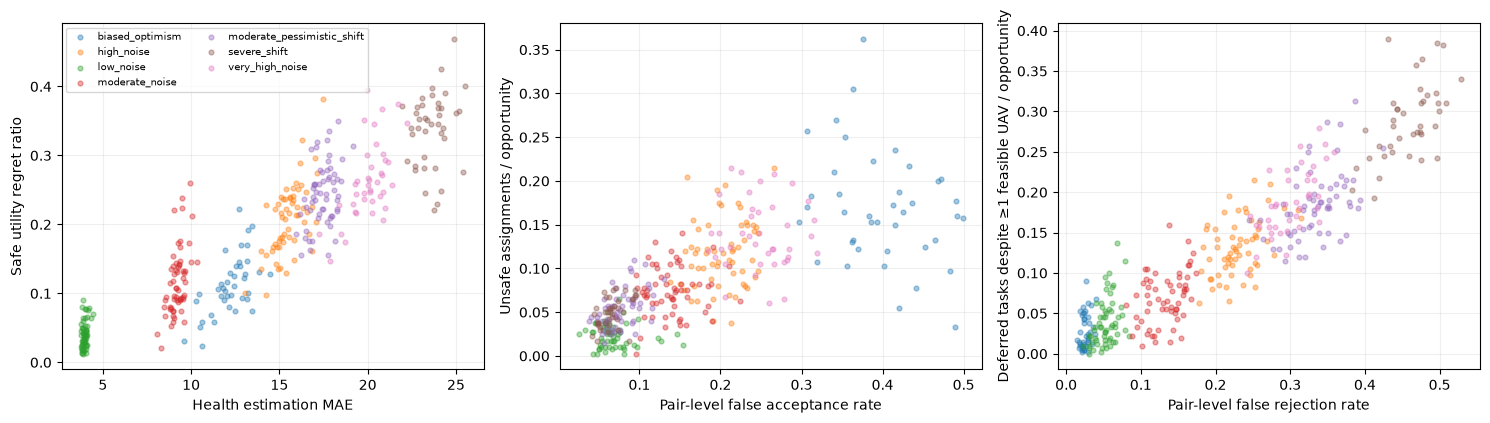

Spearman associations (descriptive):


,estimation_bias,estimation_mae,sigma_1_coverage,eligibility_fpr,eligibility_fnr,unsafe_per_opportunity,missed_feasible_task_rate,safe_utility_regret_ratio
estimation_bias,1.000,-0.752,0.126,0.432,-0.902,0.252,-0.826,-0.728
estimation_mae,-0.752,1.000,-0.189,0.051,0.869,0.295,0.857,0.908
sigma_1_coverage,0.126,-0.189,1.000,0.309,-0.107,0.145,-0.086,-0.159
eligibility_fpr,0.432,0.051,0.309,1.000,-0.315,0.801,-0.255,-0.009
eligibility_fnr,-0.902,0.869,-0.107,-0.315,1.000,0.008,0.926,0.879
unsafe_per_opportunity,0.252,0.295,0.145,0.801,0.008,1.000,0.076,0.338
missed_feasible_task_rate,-0.826,0.857,-0.086,-0.255,0.926,0.076,1.000,0.894
safe_utility_regret_ratio,-0.728,0.908,-0.159,-0.009,0.879,0.338,0.894,1.000


In [6]:
candidate=runs[runs.policy=='M1S1C1'].copy()
association=candidate[['estimation_bias','estimation_mae','sigma_1_coverage',
                       'eligibility_fpr','eligibility_fnr','unsafe_per_opportunity',
                       'missed_feasible_task_rate','safe_utility_regret_ratio']].corr(method='spearman')
association.to_csv(os.path.join(OUT,'decision_reliability_associations.csv'))
fig,axes=plt.subplots(1,3,figsize=(15,4.2))
for name,group in candidate.groupby('scenario'):
    axes[0].scatter(group.estimation_mae,group.safe_utility_regret_ratio,s=12,alpha=.4,label=name)
    axes[1].scatter(group.eligibility_fpr,group.unsafe_per_opportunity,s=12,alpha=.4)
    axes[2].scatter(group.eligibility_fnr,group.missed_feasible_task_rate,s=12,alpha=.4)
axes[0].set(xlabel='Health estimation MAE',ylabel='Safe utility regret ratio')
axes[1].set(xlabel='Pair-level false acceptance rate',ylabel='Unsafe assignments / opportunity')
axes[2].set(xlabel='Pair-level false rejection rate',ylabel='Deferred tasks despite ≥1 feasible UAV / opportunity')
axes[0].legend(fontsize=7,ncol=2)
for ax in axes:ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(os.path.join(OUT,'decision_reliability_error_propagation.png'),dpi=180)
plt.show()
print('Spearman associations (descriptive):');display(association.round(3))

## 6. Optional exact cross-check against Experiment 11 results

If you upload `FIMCAP_Experiment_11_Results.zip` to Colab, the notebook checks all five original metrics per scenario, policy, and replication. This step is optional but strongly recommended for a code audit. It does not affect the analysis.

In [7]:
import glob,zipfile
files=glob.glob('/content/*Experiment_11_Results.zip')+glob.glob('*Experiment_11_Results.zip')
if files:
    with zipfile.ZipFile(files[0]) as z:
        matching=[x for x in z.namelist() if x.endswith('experiment11_runs.csv')]
        if matching:
            import io
            original=pd.read_csv(io.BytesIO(z.read(matching[0])))
            key=['cohort','scenario','rep','policy']
            merged=runs.merge(original,on=key,suffixes=('_new','_old'),validate='one_to_one')
            assert len(merged)==len(runs)
            for metric in ['unsafe_per_opportunity','safe_utility_ratio','deferral_rate','critical_safe_rate','switches']:
                assert np.allclose(merged[metric+'_new'],merged[metric+'_old']),metric
            print('PASS: All 2,880 records match Experiment 11 for five original metrics.')
        else: print('ZIP found, but original run CSV not found.')
else:print('No Experiment 11 ZIP uploaded; internal code-level smoke test already passed.')

PASS: All 2,880 records match Experiment 11 for five original metrics.


## 7. Interpretation guardrails and export

**Decision gate:** Does estimator error explain decision errors beyond predictable conservatism? Look for consistent patterns across scenarios, intervals, and no-margin comparisons. If the only result is that larger margins reduce false acceptance while increasing false rejection, that is a predictable trade-off, not sufficient novelty.

**Limitations:** synthetic scalar capability; arbitrary task thresholds; fixed 5×5×80 setting; the same world family as Experiment 11; 1σ coverage is not calibration of fault probability; per-step oracle is a privileged benchmark; no real UAV flight validation.

The audit can support a reliability analysis, but **does not automatically establish journal novelty**.

In [8]:
metadata={'experiment':'Decision-Level Reliability Audit','source_model':'Experiment 11 exact world and allocator',
          'seed':SEED,'reps_main':REPS_MAIN,'reps_robust':REPS_ROBUST,
          'policies':CONFIGS,'scenarios':{**SCENARIOS,**ROBUST_SCENARIOS},
          'oracle':'per-step latent true capability; maximizes safe task values without switching cost',
          'warnings':['synthetic scalar capability','oracle is privileged upper bound',
                      'eligibility false rejection is not equivalent to unnecessary task deferral',
                      'coverage diagnostic is not probability calibration']}
with open(os.path.join(OUT,'decision_reliability_methodology.json'),'w') as f:json.dump(metadata,f,indent=2)
archive='Decision_Reliability_Audit_Results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(os.listdir(OUT)):z.write(os.path.join(OUT,file),arcname=file)
print('Results:',archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:pass

Results: Decision_Reliability_Audit_Results.zip
